Código adaptado de:

[1] Aurélien Géron, Hands-On Machine Learning with Scikit-Learn: Concepts, Tools and Techniques to Build Intelligent Systems, Keras & tensorFlow, Third Edition, O'Reilly, 2023.

# Laboratório 7: Autoencoders

## Bibliotecas

In [1]:
! pip install torchinfo

In [2]:
import sys                                                  # importa acesso a informações do sistema
import os                                                   # importa utilidades de sistema de arquivos
import numpy as np                                          # importa Numpy
import torch                                                # importa PyTorch
import torch.nn as nn                                       # importa módulos de redes neurais
import torch.optim as optim                                 # importa otimizadores
from torch.utils.data import DataLoader, TensorDataset      # importa utilitários de dados
from torchvision import datasets                            # importa datasets
from torchinfo import summary                               # importa função para exibir resumo das arquiteturas de rede
import matplotlib.pyplot as plt                             # importa biblioteca de gráficos
import matplotlib as mpl                                    # importa configurações avançadas de gráficos Matplotlib
from scipy.spatial.transform import Rotation                # importa rotação 3D para gerar dados sintéticos
from tqdm.auto import tqdm                                  # importa tqdm adaptável (funciona em terminal e notebook)
torch.manual_seed(42)                                       # fixa semente do PyTorch para reprodutibilidade
np.random.seed(42)                                          # fixa semente do NumPy para reprodutibilidade

/Users/gilcesarf/git/repositories/imd/imd3004-202602/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Hiperparâmetros

In [3]:
Z_DIM = 2
Z_DIM_DENOISING_AE = 30
Z_DIM_SPARSE_AE = 300
N_EPOCHS = 100
BATCH_SIZE_TRAIN = 128
BATCH_SIZE_VALID = 256
# ajusta para funcionar tanto em macos quanto no colab
#device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # escolhe GPU se disponível
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"

# Exibe qual dispositivo está sendo utilizado
print(f"Usando {device}.")


Usando mps.


## Autoencoder Linear

### Dados

In [4]:
# Geração de dados
m = 60                                                          # número de amostras
X = np.zeros((m, 3), dtype=np.float32)                          # aloca matriz 3D
angles = (np.random.rand(m) ** 3 + 0.5) * 2 * np.pi             # gera ângulos com distribuição não uniforme
X[:, 0], X[:, 1] = np.cos(angles), np.sin(angles) * 0.5         # projeta em oval no plano XY
X += 0.28 * np.random.randn(m, 3).astype(np.float32)            # adiciona ruído gaussiano
X = (Rotation.from_rotvec([np.pi / 29, -np.pi / 20, np.pi / 4]) # aplica rotação 3D
     .apply(X)
     .astype(np.float32))
X_train = X + np.array([0.2, 0.0, 0.2], dtype=np.float32)       # desloca levemente os dados

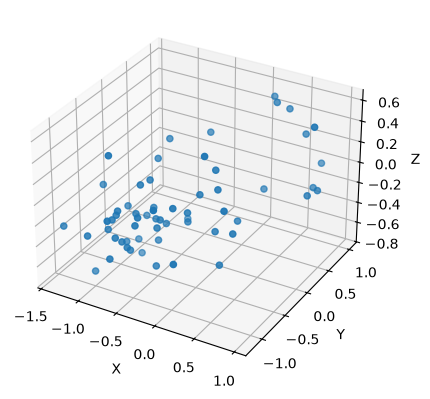

In [5]:
# Visualização 3D dos dados
fig = plt.figure(figsize=(6, 4))            # cria figura
ax = fig.add_subplot(111, projection='3d')  # cria eixo 3D
ax.scatter(X[:, 0], X[:, 1], X[:, 2])       # plota dispersão 3D
ax.set_xlabel('X')                          # rótulo eixo X
ax.set_ylabel('Y')                          # rótulo eixo Y
ax.set_zlabel('Z')                          # rótulo eixo Z
plt.tight_layout()                          # layout compacto
plt.show()                                  # exibe gráfico

In [6]:
# Dataset e DataLoader
X_train_t = torch.from_numpy(X_train)                                       # converte numpy para tensor
train_ds_linear = TensorDataset(X_train_t, X_train_t)                       # cria dataset com entrada=alvo
train_dl_linear = DataLoader(train_ds_linear, batch_size=m, shuffle=True)   # carrega tudo como um único lote

### Rede Neural

In [7]:
# Definição do autoencoder linear
encoder_linear = nn.Sequential(nn.Linear(3, 2, bias=True))          # codificador linear
decoder_linear = nn.Sequential(nn.Linear(2, 3, bias=True))          # decodificador linear
class LinearAE(nn.Module):                                          # define classe de AE linear
    def __init__(self, enc, dec):                                   # construtor recebe encoder e decoder
        super().__init__()                                          # inicializa classe base
        self.encoder = enc                                          # armazena encoder
        self.decoder = dec                                          # armazena decoder
    def forward(self, x):                                           # define passagem direta
        z = self.encoder(x)                                         # codifica entrada
        x_hat = self.decoder(z)                                     # decodifica código
        return x_hat, z                                             # retorna reconstrução e código
ae_linear = LinearAE(encoder_linear, decoder_linear).to(device)     # instancia modelo no dispositivo

In [9]:
# Inspecionar
 # mostra resumo do AE linear
summary(ae_linear, input_size=(1, 3), col_names=("input_size", "output_size", "num_params"), device=device) # adiciona device=device para nao tirar o modelo da gpu

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
LinearAE                                 [1, 3]                    [1, 3]                    --
├─Sequential: 1-1                        [1, 3]                    [1, 2]                    --
│    └─Linear: 2-1                       [1, 3]                    [1, 2]                    8
├─Sequential: 1-2                        [1, 2]                    [1, 3]                    --
│    └─Linear: 2-2                       [1, 2]                    [1, 3]                    9
Total params: 17
Trainable params: 17
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00

In [10]:
# Inspecionar
# mostra resumo do encoder linear
summary(encoder_linear, input_size=(1, 3), col_names=("input_size", "output_size", "num_params"), device=device) # adiciona device=device para nao tirar o modelo da gpu

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                               [1, 3]                    [1, 2]                    --
├─Linear: 1-1                            [1, 3]                    [1, 2]                    8
Total params: 8
Trainable params: 8
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00

In [11]:
# Inspecionar
# mostra resumo do decoder linear
summary(decoder_linear, input_size=(1, 2), col_names=("input_size", "output_size", "num_params"), device=device) # adiciona device=device para nao tirar o modelo da gpu


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                               [1, 2]                    [1, 3]                    --
├─Linear: 1-1                            [1, 2]                    [1, 3]                    9
Total params: 9
Trainable params: 9
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00

### Treinamento

In [12]:
criterion = nn.MSELoss()                                # define perda MSE
optimizer = optim.SGD(ae_linear.parameters(), lr=0.5)   # define otimizador

In [13]:
ae_linear.train()                       # coloca o modelo em modo de treino
epochs = 500                            # número de épocas
for epoch in range(epochs):             # itera sobre épocas
    for xb, yb in train_dl_linear:      # itera sobre lotes
        xb = xb.to(device)              # move entrada para dispositivo
        yb = yb.to(device)              # move alvo para dispositivo
        optimizer.zero_grad()           # zera gradientes
        x_hat, z = ae_linear(xb)        # faz forward
        loss = criterion(x_hat, yb)     # calcula perda
        loss.backward()                 # retropropaga gradientes
        optimizer.step()                # atualiza parâmetros

In [14]:
# Códigos latentes do conjunto de treinamento
ae_linear.eval()                                                    # modo de avaliação
with torch.no_grad():                                               # desabilita gradientes
    _, codings = ae_linear(torch.from_numpy(X_train).to(device))    # calcula códigos
codings = codings.cpu().numpy()                                     # move para CPU como numpy

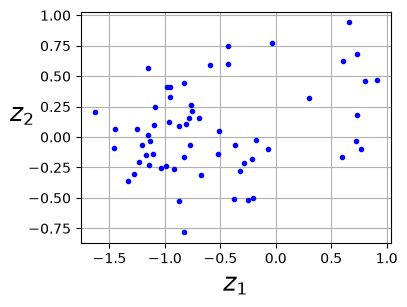

In [15]:
# Gráfico de dispersão dos códigos
fig = plt.figure(figsize=(4, 3))                # cria figura
plt.plot(codings[:, 0], codings[:, 1], "b.")    # plota códigos
plt.xlabel("$z_1$", fontsize=18)                # rótulo eixo z1
plt.ylabel("$z_2$", fontsize=18, rotation=0)    # rótulo eixo z2
plt.grid(True)                                  # exibe grade
plt.show()                                      # exibe

## Autoencoders profundos

### Dados

In [16]:
# Carregar Fashion-MNIST
train_full  = datasets.FashionMNIST(root="data", train=True, download=True)     # carrega conjunto de treinamento
test_ds     = datasets.FashionMNIST(root="data", train=False, download=True)    # carrega conjunto de teste
X_full = train_full.data.float() / 255.0                                        # normaliza imagens de treinamento
y_full = train_full.targets.long()                                              # rótulos de treinamento
X_test = test_ds.data.float() / 255.0                                           # normaliza imagens de teste
y_test = test_ds.targets.long()                                                 # rótulos de teste

In [17]:
print(f'X_full shape: {X_full.shape} | min={X_full.min()} | max={X_full.max()}')
print(f'y_full shape: {y_full.shape}')
print(f'X_test shape: {X_test.shape} | min={X_test.min()} | max={X_test.max()}')
print(f'y_test shape: {y_test.shape}')

X_full shape: torch.Size([60000, 28, 28]) | min=0.0 | max=1.0
y_full shape: torch.Size([60000])
X_test shape: torch.Size([10000, 28, 28]) | min=0.0 | max=1.0
y_test shape: torch.Size([10000])


In [18]:
X_train = X_full[:-5000]                                                        # fatia X treinamento
y_train = y_full[:-5000]                                                        # fatia y rótulos
X_valid = X_full[-5000:]                                                        # fatia X validação
y_valid = y_full[-5000:]                                                        # fatia y rótulos

In [19]:
print(f'X_train shape: {X_train.shape} | min={X_train.min()} | max={X_train.max()}')
print(f'y_train shape: {y_train.shape}')
print(f'X_valid shape: {X_valid.shape} | min={X_valid.min()} | max={X_valid.max()}')
print(f'y_valid shape: {y_valid.shape}')

X_train shape: torch.Size([55000, 28, 28]) | min=0.0 | max=1.0
y_train shape: torch.Size([55000])
X_valid shape: torch.Size([5000, 28, 28]) | min=0.0 | max=1.0
y_valid shape: torch.Size([5000])


In [20]:
X_train = X_train.unsqueeze(1)                                                  # adiciona canal para shape [batch, channels, height, width] (ou (B, C, H, W))
X_valid = X_valid.unsqueeze(1)                                                  # adiciona canal para shape [batch, channels, height, width] (ou (B, C, H, W))
X_test  = X_test.unsqueeze(1)                                                   # adiciona canal para shape [batch, channels, height, width] (ou (B, C, H, W))

In [21]:
print(f'X_train shape: {X_train.shape} | min={X_train.min()} | max={X_train.max()}')
print(f'X_valid shape: {X_valid.shape} | min={X_valid.min()} | max={X_valid.max()}')
print(f'X_test shape: {X_test.shape} | min={X_test.min()} | max={X_test.max()}')

X_train shape: torch.Size([55000, 1, 28, 28]) | min=0.0 | max=1.0
X_valid shape: torch.Size([5000, 1, 28, 28]) | min=0.0 | max=1.0
X_test shape: torch.Size([10000, 1, 28, 28]) | min=0.0 | max=1.0


In [22]:
train_ds = TensorDataset(X_train, X_train)                                      # conjunto de treinamento
valid_ds = TensorDataset(X_valid, X_valid)                                      # conjunto de validação
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE_TRAIN, shuffle=True)      # dataloader de treinamento
valid_dl = DataLoader(valid_ds, batch_size=BATCH_SIZE_VALID, shuffle=False)     # dataloader de validação

### Funções de visualização

In [23]:
# plota imagens originais e reconstruções
def plot_reconstructions(model, images_tensor, n_images=5, apply_clip=True):
    model.eval()                                            # modo avaliação
    with torch.no_grad():                                   # sem gradientes
        x = images_tensor[:n_images].to(device)             # seleciona amostras
        x_hat, _ = model(x)                                 # obtém reconstruções
        x = x.detach().cpu().numpy()                        # move para CPU
        x_hat = x_hat.detach().cpu().numpy()                # move para CPU
        if apply_clip:                                      # aplica clipping opcional
            x_hat = np.clip(x_hat, 0, 1)                    # garante faixa [0,1]
    fig = plt.figure(figsize=(n_images * 1.5, 3))           # cria figura
    for i in range(n_images):                               # itera imagens
        plt.subplot(2, n_images, 1 + i)                     # subplot imagem original
        plt.imshow(x[i].squeeze(0), cmap="binary")          # exibe imagem original
        plt.axis("off")                                     # oculta eixos
        plt.subplot(2, n_images, 1 + n_images + i)          # subplot reconstrução
        plt.imshow(x_hat[i], cmap="binary")                 # exibe reconstrução
        plt.axis("off")                                     # oculta eixos
    plt.show()                                              # exibe

In [24]:
def extrair_codigos(model, X_tensor, batch_size=256, device='cuda'):
    model.eval()  # modo avaliação
    with torch.no_grad():  # sem gradientes
        Z = []  # lista para códigos
        for i in range(0, X_tensor.size(0), batch_size):  # itera em blocos
            xb = X_tensor[i:i+batch_size].to(device)  # pega bloco
            _, z = model(xb)  # extrai código
            Z.append(z.cpu().numpy())  # acumula como numpy
        Z = np.concatenate(Z, axis=0)  # concatena todos
    return Z

def plot_latent_space_2d(model, X_valid, y_valid, batch_size=256, device='cuda'):

    Z = extrair_codigos(model, X_valid, batch_size=batch_size, device=device)

    plt.figure(figsize=(10, 8))
    cmap = plt.cm.tab10
    Z = (Z - Z.min()) / (Z.max() - Z.min())  # normalize to the 0-1 range
    plt.scatter(Z[:, 0], Z[:, 1], c=y_valid, s=10, cmap=cmap)
    image_positions = np.array([[1., 1.]])
    for index, position in enumerate(Z):
        dist = ((position - image_positions) ** 2).sum(axis=1)
        if dist.min() > 0.02: # if far enough from other images
            image_positions = np.r_[image_positions, [position]]

            # Adiciona imagem
            imagebox = mpl.offsetbox.AnnotationBbox(
                mpl.offsetbox.OffsetImage(X_valid[index].squeeze(0), cmap="binary"),
                position, bboxprops={"edgecolor": cmap(y_valid[index]), "lw": 2})
            plt.gca().add_artist(imagebox)


            # Escreve as coordenadas [z1, z2] acima da imagem
            z1, z2 = position
            plt.text(
                z1, z2 + 0.05,                    # ligeiramente acima da imagem
                f"[{z1:.2f}, {z2:.2f}]",          # formatação com 2 casas decimais
                fontsize=8, fontweight='bold', ha="center", va="bottom",
                color='k'        # mesma cor da borda
            )

    plt.axis("off")
    plt.show()

### Autoencoders convolucionais

#### Rede Neural

In [25]:
# codificador convolucional: (N, 1, 28, 28) -> (N, Z_DIM)
class ConvEncoder(nn.Module):
    def __init__(self):                                                         # define as camadas do codificador
        super().__init__()                                                      # inicializa a classe base nn.Module
        self.net = nn.Sequential(                                               # convoluções e camadas de pooling: 28x28 -> 14x14 -> 7x7 -> 3x3 -> 1x1
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=64, out_channels=Z_DIM, kernel_size=3, padding=1),
            nn.AdaptiveAvgPool2d(output_size=(1, 1)),                           # output_size=(H, W); reduz cada mapa à sua média [global average pooling] -> (N, Z_DIM, 1, 1)
        )
    def forward(self, x):                                                       # define a passagem direta [forward pass] para x de shape (N, 1, 28, 28)
        x = self.net(x)                                                         # aplica a sequência de camadas -> (N, Z_DIM, 1, 1)
        z = x.view(x.shape[0], -1)                                              # achata [flatten] mantendo o lote; o -1 infere Z_DIM -> (N, Z_DIM)
        return z                                                                # retorna o código latente z, de shape (N, Z_DIM)

# decodificador convolucional: (N, Z_DIM) -> (N, 28, 28)
class ConvDecoder(nn.Module):
    def __init__(self):                                                         # define as camadas do decodificador
        super().__init__()                                                      # inicializa a classe base nn.Module
        self.fc = nn.Linear(in_features=Z_DIM, out_features=3 * 3 * 16)         # projeta o código latente em 3 * 3 * 16 valores (16 mapas 3x3)
        self.net = nn.Sequential(                                               # convoluções transpostas [transposed convolutions]: 3x3 -> 7x7 -> 14x14 -> 28x28
            nn.ConvTranspose2d(in_channels=16, out_channels=32, kernel_size=3, stride=2),
            nn.ReLU(),
            nn.ConvTranspose2d(in_channels=32, out_channels=16, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(in_channels=16, out_channels=1, kernel_size=3, stride=2, padding=1, output_padding=1),
        )
    def forward(self, z):                                                       # define a passagem direta para z de shape (N, Z_DIM)
        x = self.fc(z)                                                          # projeta o código latente -> (N, 144)
        x = x.view(-1, 16, 3, 3)                                                # remodela em 16 mapas 3x3; o -1 infere N -> (N, 16, 3, 3)
        x = self.net(x)                                                         # aplica as convoluções transpostas -> (N, 1, 28, 28)
        x = x.squeeze(1)                                                        # remove a dimensão do canal -> (N, 28, 28), como o alvo yb em treinar_ae
        return x                                                                # retorna a reconstrução, de shape (N, 28, 28), não limitada a [0, 1]

# autoencoder convolucional: (N, 1, 28, 28) -> (N, 28, 28)
class ConvAE(nn.Module):
    def __init__(self):                                                         # define o codificador e o decodificador
        super().__init__()                                                      # inicializa a classe base nn.Module
        self.encoder = ConvEncoder()                                            # instancia o codificador
        self.decoder = ConvDecoder()                                            # instancia o decodificador
    def forward(self, x):                                                       # define a passagem direta para x de shape (N, 1, 28, 28)
        z = self.encoder(x)                                                     # codifica a imagem no código latente -> (N, Z_DIM)
        x_hat = self.decoder(z)                                                 # reconstrói a imagem a partir do código -> (N, 28, 28)
        return x_hat, z                                                         # retorna a reconstrução e o código, interface comum aos três autoencoders

conv_ae = ConvAE().to(device)                                                   # instancia o autoencoder e move seus parâmetros para device

In [26]:
# Inspecionar
summary(conv_ae,                                                                # mostra resumo do AE conv
        input_size=(1, 1, 28, 28),
        col_names=("input_size", "output_size", "num_params"), device=device)   # adiciona device=device para nao tirar o modelo da gpu

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
ConvAE                                   [1, 1, 28, 28]            [1, 28, 28]               --
├─ConvEncoder: 1-1                       [1, 1, 28, 28]            [1, 2]                    --
│    └─Sequential: 2-1                   [1, 1, 28, 28]            [1, 2, 1, 1]              --
│    │    └─Conv2d: 3-1                  [1, 1, 28, 28]            [1, 16, 28, 28]           160
│    │    └─ReLU: 3-2                    [1, 16, 28, 28]           [1, 16, 28, 28]           --
│    │    └─MaxPool2d: 3-3               [1, 16, 28, 28]           [1, 16, 14, 14]           --
│    │    └─Conv2d: 3-4                  [1, 16, 14, 14]           [1, 32, 14, 14]           4,640
│    │    └─ReLU: 3-5                    [1, 32, 14, 14]           [1, 32, 14, 14]           --
│    │    └─MaxPool2d: 3-6               [1, 32, 14, 14]           [1, 32, 7, 7]             --
│    │    └─Conv2d: 3-7        

In [27]:
# Inspecionar
summary(conv_ae.encoder,                                                        # mostra resumo do encoder conv
        input_size=(1, 1, 28, 28),
        col_names=("input_size", "output_size", "num_params"), device=device)   # adiciona device=device para nao tirar o modelo da gpu

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
ConvEncoder                              [1, 1, 28, 28]            [1, 2]                    --
├─Sequential: 1-1                        [1, 1, 28, 28]            [1, 2, 1, 1]              --
│    └─Conv2d: 2-1                       [1, 1, 28, 28]            [1, 16, 28, 28]           160
│    └─ReLU: 2-2                         [1, 16, 28, 28]           [1, 16, 28, 28]           --
│    └─MaxPool2d: 2-3                    [1, 16, 28, 28]           [1, 16, 14, 14]           --
│    └─Conv2d: 2-4                       [1, 16, 14, 14]           [1, 32, 14, 14]           4,640
│    └─ReLU: 2-5                         [1, 32, 14, 14]           [1, 32, 14, 14]           --
│    └─MaxPool2d: 2-6                    [1, 32, 14, 14]           [1, 32, 7, 7]             --
│    └─Conv2d: 2-7                       [1, 32, 7, 7]             [1, 64, 7, 7]             18,496
│    └─ReLU: 2-8           

In [28]:
# Inspecionar
summary(conv_ae.decoder,                                                        # mostra resumo do decoder conv
        input_size=(1, Z_DIM),
        col_names=("input_size", "output_size", "num_params"), device=device)   # adiciona device=device para nao tirar o modelo da gpu

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
ConvDecoder                              [1, 2]                    [1, 28, 28]               --
├─Linear: 1-1                            [1, 2]                    [1, 144]                  432
├─Sequential: 1-2                        [1, 16, 3, 3]             [1, 1, 28, 28]            --
│    └─ConvTranspose2d: 2-1              [1, 16, 3, 3]             [1, 32, 7, 7]             4,640
│    └─ReLU: 2-2                         [1, 32, 7, 7]             [1, 32, 7, 7]             --
│    └─ConvTranspose2d: 2-3              [1, 32, 7, 7]             [1, 16, 14, 14]           4,624
│    └─ReLU: 2-4                         [1, 16, 14, 14]           [1, 16, 14, 14]           --
│    └─ConvTranspose2d: 2-5              [1, 16, 14, 14]           [1, 1, 28, 28]            145
Total params: 9,841
Trainable params: 9,841
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 1.25
Input size (MB)

#### Treinamento

In [29]:
criterion = nn.MSELoss()                                                        # define perda MSE
optimizer = optim.NAdam(conv_ae.parameters(), lr=0.002)                         # define otimizador

In [30]:
# Loop de treinamento
def treinar_ae(model, train_dl, valid_dl, optimizer, criterion, epochs=100, l1_regularization=False, lambda_l1=1e-4, device=device):

    train_hist = []                                                             # histórico treinamento
    valid_hist = []                                                             # histórico validação

    progress_bar = tqdm(range(epochs), desc="Época")

    # ---------------------- TREINAMENTO ----------------------
    for _ in progress_bar:                      # itera épocas
        model.train()                           # modo treinamento
        running, n = 0.0, 0                     # acumuladores
        for xb, yb in train_dl:                 # itera lotes de treinamento
            xb = xb.to(device)                  # move entrada
            yb = yb.squeeze(1).to(device)       # remove canal para shape (N,28,28)
            optimizer.zero_grad()               # zera gradientes
            x_hat, z = model(xb)                # forward

            # calcula perda
            if l1_regularization:
                loss = criterion(x_hat, yb) + lambda_l1 * z.abs().mean()
            else:
                loss = criterion(x_hat, yb)

            loss.backward()                     # retropropaga
            optimizer.step()                    # atualiza
            running += loss.item() * xb.size(0) # acumula perda
            n += xb.size(0)                     # acumula amostras
        train_loss = running / n
        train_hist.append(train_loss)           # guarda perda média

        # ---------------------- VALIDAÇÃO ----------------------
        model.eval()                                # modo avaliação
        with torch.no_grad():                       # sem gradientes
            running, n = 0.0, 0                     # zera acumuladores
            for xb, yb in valid_dl:                 # itera lotes de validação
                xb = xb.to(device)                  # move entrada
                yb = yb.squeeze(1).to(device)       # remove canal
                x_hat, _ = model(xb)                # forward
                loss = criterion(x_hat, yb)         # perda
                running += loss.item() * xb.size(0) # acumula
                n += xb.size(0)                     # acumula
            valid_loss = running / n
            valid_hist.append(valid_loss)           # guarda perda média

        progress_bar.set_postfix({
            "Train": f"{train_loss:.4f}",
            "Val": f"{valid_loss:.4f}"
        })

    return train_hist, valid_hist

In [31]:
def curvas_de_treinamento(train_hist, valid_hist):
    plt.figure(figsize=(5,3))                   # cria figura
    plt.plot(train_hist, label="treinamento")   # plota perda de treinamento
    plt.plot(valid_hist, label="validação")     # plota perda de validação
    plt.xlabel("Época")                         # rótulo eixo x
    plt.ylabel("MSE")                           # rótulo eixo y
    plt.legend()                                # legenda
    plt.grid(True)                              # grade
    plt.tight_layout()                          # layout
    plt.show()                                  # exibe

In [32]:
train_hist, valid_hist = treinar_ae(conv_ae, train_dl, valid_dl, optimizer, criterion, epochs=N_EPOCHS, device=device)

Época: 100%|██████████| 100/100 [04:14<00:00,  2.54s/it, Train=0.0282, Val=0.0291]


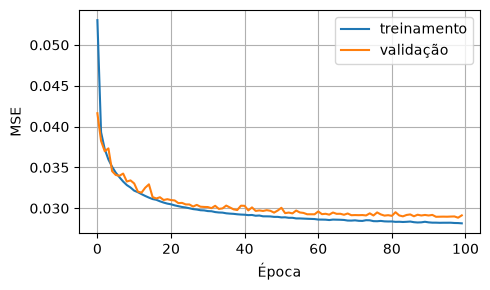

In [33]:
curvas_de_treinamento(train_hist, valid_hist)

#### Visualizações

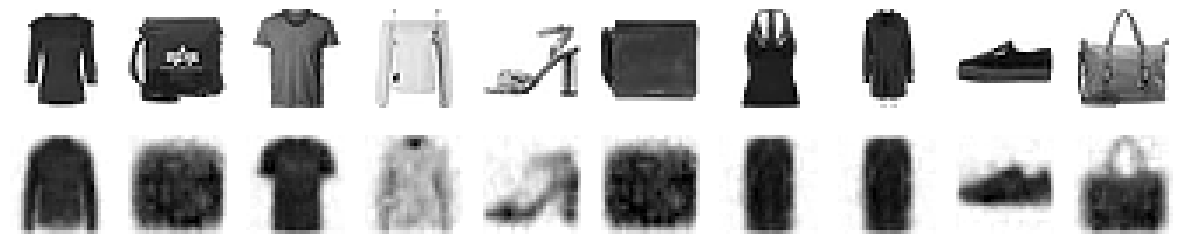

In [34]:
# Visualização de reconstruções
plot_reconstructions(conv_ae, X_valid.float(), n_images=10, apply_clip=True)    # mostra amostras

In [ ]:
plot_latent_space_2d(conv_ae, X_valid, y_valid, batch_size=256, device=device)

### Denoising Autoencoders

#### Rede Neural

In [35]:
# Encoder com dropout
class DropoutEncoder(nn.Module):
    def __init__(self, p=0.5):              # construtor com probabilidade
        super().__init__()                  # base
        self.net = nn.Sequential(           # sequência de camadas
            nn.Flatten(),
            nn.Dropout(p=p),
            nn.Linear(28*28, 100),
            nn.ReLU(),
            nn.Linear(100, Z_DIM_DENOISING_AE),
            nn.ReLU())
    def forward(self, x):                   # forward
        return self.net(x)                  # retorna código

# Decoder denso
class DropoutDecoder(nn.Module):
    def __init__(self):                     # construtor
        super().__init__()                  # base
        self.net = nn.Sequential(           # sequência de camadas
            nn.Linear(Z_DIM_DENOISING_AE, 100),
            nn.ReLU(),
            nn.Linear(100, 28*28),
        )
    def forward(self, z):                   # forward
        x = self.net(z)                     # aplica camadas
        x = x.view(-1, 28, 28)              # reshape para imagem
        return x                            # retorna reconstrução

# Denoising AE
class DropoutAE(nn.Module):
    def __init__(self, p=0.5):              # construtor
        super().__init__()                  # base
        self.encoder = DropoutEncoder(p=p)  # instancia encoder
        self.decoder = DropoutDecoder()     # instancia decoder
    def forward(self, x):                   # forward
        z = self.encoder(x)                 # codifica
        x_hat = self.decoder(z)             # decodifica
        return x_hat, z                     # retorna reconstrução e código

dropout_ae = DropoutAE(p=0.5).to(device)  # instancia AE com dropout 0.5

In [36]:
# Inspecionar
# mostra resumo do AE conv
summary(dropout_ae, input_size=(1, 1, 28, 28), col_names=("input_size", "output_size", "num_params"), device=device)   # adiciona device=device para nao tirar o modelo da gpu

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
DropoutAE                                [1, 1, 28, 28]            [1, 28, 28]               --
├─DropoutEncoder: 1-1                    [1, 1, 28, 28]            [1, 30]                   --
│    └─Sequential: 2-1                   [1, 1, 28, 28]            [1, 30]                   --
│    │    └─Flatten: 3-1                 [1, 1, 28, 28]            [1, 784]                  --
│    │    └─Dropout: 3-2                 [1, 784]                  [1, 784]                  --
│    │    └─Linear: 3-3                  [1, 784]                  [1, 100]                  78,500
│    │    └─ReLU: 3-4                    [1, 100]                  [1, 100]                  --
│    │    └─Linear: 3-5                  [1, 100]                  [1, 30]                   3,030
│    │    └─ReLU: 3-6                    [1, 30]                   [1, 30]                   --
├─DropoutDecoder: 1-2       

In [37]:
# Inspecionar
# mostra resumo do encoder conv
summary(dropout_ae.encoder, input_size=(1, 1, 28, 28), col_names=("input_size", "output_size", "num_params"), device=device)   # adiciona device=device para nao tirar o modelo da gpu

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
DropoutEncoder                           [1, 1, 28, 28]            [1, 30]                   --
├─Sequential: 1-1                        [1, 1, 28, 28]            [1, 30]                   --
│    └─Flatten: 2-1                      [1, 1, 28, 28]            [1, 784]                  --
│    └─Dropout: 2-2                      [1, 784]                  [1, 784]                  --
│    └─Linear: 2-3                       [1, 784]                  [1, 100]                  78,500
│    └─ReLU: 2-4                         [1, 100]                  [1, 100]                  --
│    └─Linear: 2-5                       [1, 100]                  [1, 30]                   3,030
│    └─ReLU: 2-6                         [1, 30]                   [1, 30]                   --
Total params: 81,530
Trainable params: 81,530
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.08
Input size (MB

In [38]:
# Inspecionar
# mostra resumo do decoder conv
summary(dropout_ae.decoder, input_size=(1, Z_DIM_DENOISING_AE), col_names=("input_size", "output_size", "num_params"), device=device)   # adiciona device=device para nao tirar o modelo da gpu

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
DropoutDecoder                           [1, 30]                   [1, 28, 28]               --
├─Sequential: 1-1                        [1, 30]                   [1, 784]                  --
│    └─Linear: 2-1                       [1, 30]                   [1, 100]                  3,100
│    └─ReLU: 2-2                         [1, 100]                  [1, 100]                  --
│    └─Linear: 2-3                       [1, 100]                  [1, 784]                  79,184
Total params: 82,284
Trainable params: 82,284
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.08
Input size (MB): 0.00
Forward/backward pass size (MB): 0.01
Params size (MB): 0.33
Estimated Total Size (MB): 0.34

#### Treinamento

In [39]:
criterion = nn.MSELoss()                                    # define perda MSE
optimizer = optim.NAdam(dropout_ae.parameters(), lr=0.002)  # define otimizador

In [40]:
train_hist, valid_hist = treinar_ae(dropout_ae, train_dl, valid_dl, optimizer, criterion, epochs=N_EPOCHS, device=device)

Época: 100%|██████████| 100/100 [02:09<00:00,  1.29s/it, Train=0.0167, Val=0.0151]


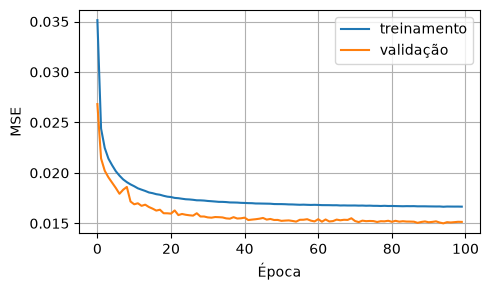

In [41]:
curvas_de_treinamento(train_hist, valid_hist)

#### Visualizações

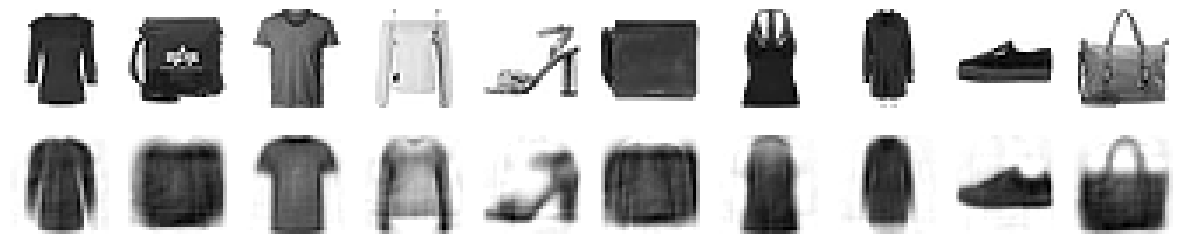

In [42]:
# Visualização de reconstruções
plot_reconstructions(dropout_ae, X_valid.float(), n_images=10, apply_clip=True) # mostra amostras

### Autoencoder Esparso

#### Rede Neural

In [43]:
# Encoder esparso
class SparseEncoder(nn.Module):
    def __init__(self):             # construtor
        super().__init__()          # base
        self.net = nn.Sequential(   # sequência
            nn.Flatten(),
            nn.Linear(28*28, 100),
            nn.ReLU(),
            nn.Linear(100, Z_DIM_SPARSE_AE),
            nn.Sigmoid(),
        )
    def forward(self, x):           # forward
        return self.net(x)          # retorna código

# Decoder esparso
class SparseDecoder(nn.Module):
    def __init__(self):             # construtor
        super().__init__()          # base
        self.net = nn.Sequential(   # sequência
            nn.Linear(Z_DIM_SPARSE_AE, 100),
            nn.ReLU(),
            nn.Linear(100, 28*28),
        )
    def forward(self, z):           # forward
        x = self.net(z)             # aplica camadas
        x = x.view(-1, 28, 28)      # reshape para imagem
        return x                    # retorna reconstrução

# AE esparso
class SparseAE(nn.Module):
    def __init__(self):                 # construtor
        super().__init__()              # base
        self.encoder = SparseEncoder()  # instancia encoder
        self.decoder = SparseDecoder()  # instancia decoder
    def forward(self, x):               # forward
        z = self.encoder(x)             # codifica
        x_hat = self.decoder(z)         # decodifica
        return x_hat, z                 # retorna reconstrução e código

sparse_ae = SparseAE().to(device)  # instancia AE esparso

#### Treinamento

In [44]:
criterion = nn.MSELoss()                                    # define perda MSE
optimizer = optim.NAdam(sparse_ae.parameters(), lr=0.002)   # define otimizador

In [45]:
train_hist, valid_hist = treinar_ae(sparse_ae, train_dl, valid_dl, optimizer, criterion, epochs=N_EPOCHS, device=device, l1_regularization=True, lambda_l1=1e-4)

Época: 100%|██████████| 100/100 [02:11<00:00,  1.31s/it, Train=0.0158, Val=0.0160]


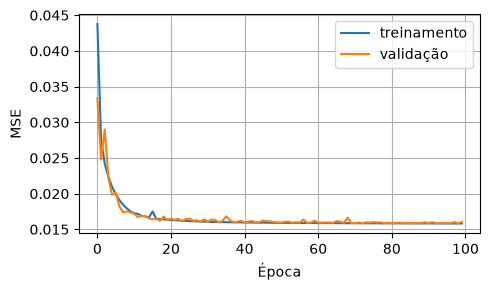

In [46]:
curvas_de_treinamento(train_hist, valid_hist)

#### Visualizações

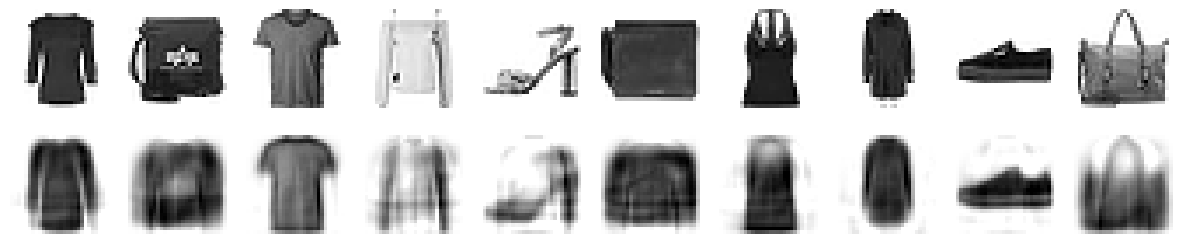

In [47]:
# Visualização de reconstruções
plot_reconstructions(sparse_ae, X_valid.float(), n_images=10, apply_clip=True)   # mostra amostras

# Tarefa (em duplas)

**Investigar o efeito da dimensão do espaço latente nas reconstruções de autoencoders convolucionais, de remoção de ruído [*denoising*] e esparsos [*sparse*] treinados com a base de dados MNIST**

Utilize o código acima como base e adapte-o conforme os itens a seguir, organizados em quatro etapas: preparação, experimentos, resultados e análise. Não apague nem reordene as células de enunciado; responda abaixo de cada **Resposta**, usando quantas células precisar.

**Observação:** para que os experimentos sejam comparáveis, treine todos por `N_EPOCHS = 100` épocas, com os mesmos `train_dl` e `valid_dl`, a mesma função de perda (`nn.MSELoss`), o mesmo otimizador (`NAdam` com `lr=0.002`) e a mesma semente aleatória (`torch.manual_seed(42)` imediatamente antes de instanciar cada modelo). Altere apenas a dimensão do espaço latente, mantendo `p=0.5` no autoencoder de remoção de ruído e `lambda_l1=1e-4` no esparso.

**Entregáveis:**

Ao final da Unidade 2, você entregará **o notebook de cada laboratório da unidade**,
um arquivo `.ipynb` por laboratório, com a tarefa respondida ao final.

Cada notebook deve **executar do início ao fim sem erros**, em um kernel novo,
com *Restart & Run All*. Antes de entregar, execute-o dessa forma e confirme
que todas as células rodam na ordem em que aparecem e que as saídas exibidas
correspondem a essa execução. Notebooks que não executarem por completo serão
penalizados.

A entrega é **única por grupo**. Identifique os integrantes no início de cada
notebook.

## Preparação

### 1. Conjunto MNIST

Substitua o conjunto *Fashion-MNIST* pelo conjunto de dígitos *MNIST*, disponível em [`torchvision.datasets`](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html#torchvision.datasets.MNIST):

```python
train_full  = datasets.MNIST(root="data", train=True, download=True)     # carrega conjunto de treinamento
test_ds     = datasets.MNIST(root="data", train=False, download=True)    # carrega conjunto de teste
```

Mostre algumas imagens de um lote de `train_dl`.

#### Resposta

### 2. Dimensão latente `z_dim` como argumento

Adapte as classes dos três autoencoders para receberem a dimensão do espaço latente como argumento do construtor, `z_dim`, no lugar das constantes globais `Z_DIM`, `Z_DIM_DENOISING_AE` e `Z_DIM_SPARSE_AE`. No convolucional, `z_dim` define o número de canais de saída da última `nn.Conv2d` de `ConvEncoder` e o número de entradas da `nn.Linear` de `ConvDecoder`, e `ConvAE(z_dim=...)` deve repassá-lo aos dois. Em `DropoutAE` e `SparseAE`, `z_dim` é o número de saídas da última `nn.Linear` do codificador e o número de entradas da primeira `nn.Linear` do decodificador.

#### Resposta

## Experimentos

### 3. Treinamento dos nove experimentos

Treine cada autoencoder com três dimensões do espaço latente, `z_dim` $\in \{2, 30, 300\}$ (os valores de `Z_DIM`, `Z_DIM_DENOISING_AE` e `Z_DIM_SPARSE_AE` no código do laboratório), totalizando nove experimentos. Em cada autoencoder, o experimento com o valor do código base (2 no convolucional, 30 no de remoção de ruído e 300 no esparso) é a **configuração base**, referência para as comparações. A função `treinar_ae` já retorna as perdas médias por época de treinamento e de validação; guarde-as para cada experimento, por exemplo em um dicionário indexado por `(modelo, z_dim)`:

```python
torch.manual_seed(42)                                     # mesma semente antes de instanciar cada modelo
modelo = ConvAE(z_dim=z_dim).to(device)                   # novo modelo a cada experimento
optimizer = optim.NAdam(modelo.parameters(), lr=0.002)    # novo otimizador: o anterior só atualiza os parâmetros do modelo anterior
historicos[("conv", z_dim)] = treinar_ae(modelo, train_dl, valid_dl, optimizer, criterion, epochs=N_EPOCHS, device=device)  # (train_hist, valid_hist)
```

Obs.: no autoencoder esparso, chame `treinar_ae` com `l1_regularization=True, lambda_l1=1e-4`, como no código do laboratório; sem esses argumentos, o modelo é treinado sem a regularização L1 que o torna esparso.

#### Resposta

## Resultados

### 4. Curvas de perda e MSE

Para cada autoencoder, adapte `curvas_de_treinamento` para plotar, no mesmo gráfico e com legenda, as curvas de perda (MSE) de treinamento e de validação das três dimensões do espaço latente. Reúna também, em uma tabela, o MSE de validação da última época (`valid_hist[-1]`) e o MSE no conjunto de teste de cada um dos nove experimentos.

Obs.: compare os experimentos pela perda de **validação**. A perda de treinamento é calculada com o *dropout* ativo (isto é, com entradas corrompidas) no de remoção de ruído e inclui o termo `lambda_l1 * z.abs().mean()` no esparso; na validação, `treinar_ae` usa `model.eval()` e apenas o MSE.

Obs.: o conjunto de **teste** não participa do treinamento nem da escolha entre configurações, que é feita pela validação. Ele é avaliado uma única vez, com cada modelo já treinado, e estima o erro de reconstrução em imagens nunca vistas.

#### Resposta

### 5. Reconstruções

**Todos os experimentos.** Crie uma variante de `plot_reconstructions` que mostre, em uma única figura, as 10 primeiras imagens de validação (`X_valid`) na primeira linha e as reconstruções dos nove modelos nas nove linhas seguintes, uma linha por modelo. Identifique cada linha com o autoencoder e o `z_dim` correspondentes, ordenando-as por autoencoder e, dentro de cada um, por `z_dim` crescente.

**Denoising autoencoder.** O autoencoder de remoção de ruído é treinado para reconstruir a imagem limpa a partir de uma entrada corrompida pelo *dropout*, que zera cerca de metade dos pixels. Mostre, em uma única figura, as 10 imagens originais, essas mesmas imagens corrompidas e, nas três linhas seguintes, as reconstruções obtidas a partir delas para cada valor de `z_dim`. Corrompa as imagens uma única vez e use a mesma entrada corrompida nos três modelos, para que as diferenças entre as linhas se devam apenas a `z_dim`:

```python
x_ruidoso = nn.Dropout(p=0.5)(x)   # corrompe a entrada como no treinamento
x_hat, _ = model(x_ruidoso)        # com model.eval(), o Dropout interno do codificador não é reaplicado
```

#### Resposta

### 6. Espaço latente 2D

Para o autoencoder convolucional com `z_dim = 2`, plote o espaço latente das imagens de validação com `plot_latent_space_2d`, como no código do laboratório.

Obs.: `plot_latent_space_2d` só se aplica a `z_dim = 2`: com dimensões maiores, ela plota, sem aviso, apenas as duas primeiras coordenadas do código latente.

#### Resposta

## Análise

Responda a cada pergunta a partir da inspeção visual das figuras e dos valores de MSE dos itens 4 a 6, indicando em quais itens a resposta se apoia.

**(a)** Como a dimensão do espaço latente afeta o MSE e a nitidez das reconstruções em cada autoencoder? Há um ponto a partir do qual aumentá-la deixa de ajudar?

**(b)** Para uma mesma dimensão do espaço latente, qual autoencoder reconstrói melhor? A ordem obtida na validação se mantém no conjunto de teste?

**(c)** Na figura de remoção de ruído do item 5, o autoencoder de remoção de ruído recupera os dígitos corrompidos? Há diferença visível entre os três valores de `z_dim`?

**(d)** Como os dígitos se organizam no espaço latente 2D do autoencoder convolucional? Quais classes ficam separadas e quais se sobrepõem?

### Resposta (a)

### Resposta (b)

### Resposta (c)

### Resposta (d)